# Notebook 1: Evidence library
**IDS 560, Group 4, M5 inventory agent (v4).** This notebook builds the library of dated evidence the agent searches, and lets you look through every passage in it.

| Notebook | What it does | Model calls |
|---|---|---|
| **1. Evidence library** (this one) | Downloads documents, builds evidence cards from the M5 data, splits them into passages, embeds them, and shows the library | none |
| 2. Retrieval tests | Searches the library as of a date; 56 test questions; compares retrieval methods | none |
| 3. Agent | Orders (forecast, flags, hold rule, new-item forecast, confidence), `recommend()` and `ask()`, validation matrices | about 30 |
| 4. Evaluation | New-item simulation, confidence check, order backtest | none |

**Run order:** 1 → 2 → 3 → 4. Run this one again only when sources or cards change; the others load what it saves.

**Shared code.** Functions used by more than one notebook (paths, data loading, search, forecasts, the agent) are in `rag_common.py` in the `RAG FILES` folder, so a fix there applies everywhere. Each notebook starts with `import rag_common as rc`.

**Files.** Everything is read from and saved to `RAG FILES/` (download cache in `RAG FILES/raw/`); saved file names end in `_v4`. M5 data comes from `M5 EDA/datasets/` and forecasting outputs from `M5 Forecasting/M5_Forecasting_Outputs/`.

## 1. Setup
Mounts Drive, loads the shared code and the M5 sales, calendar and price data (about a minute). `from rag_common import *` makes the shared functions and data usable by name below.

In [ ]:
!pip -q install sentence-transformers openai pypdf
import sys, importlib
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
RAG_FILES = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/"   # rag_common.py lives here
sys.path.insert(0, RAG_FILES)
import rag_common as rc
importlib.reload(rc)
rc.setup(m5=True, forecasts=False, library=False)
from rag_common import *
from bs4 import BeautifulSoup

Mounted at /content/drive
M5 data: 30,490 series x 1,941 days | prices for 79% of series-weeks
Setup done in 23s | files are read from and saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/ (names end in _v4)


## 2. Settings for the downloads and cards

In [ ]:
# The SEC requires automated downloads to identify who is running them (name + contact email); it is only sent to sec.gov
SEC_USER_AGENT = "IDS560 Group 4 student project your.name@uic.edu"
WALMART_CIK = "0000104169"
# NOAA storm types kept (hail and thunderstorm wind are left out: thousands of very local reports with little retail effect)
STORM_TYPES = {
    "Winter Storm", "Heavy Snow", "Blizzard", "Ice Storm", "Winter Weather", "Lake-Effect Snow", "Sleet",
    "Extreme Cold/Wind Chill", "Cold/Wind Chill", "Frost/Freeze",
    "Excessive Heat", "Heat", "Drought", "Wildfire",
    "Flood", "Flash Flood", "Heavy Rain", "Coastal Flood",
    "Tropical Storm", "Hurricane", "Tropical Depression", "Storm Surge/Tide",
    "High Wind", "Strong Wind", "Tornado", "Dust Storm",
}
# Beige Book districts kept, and the M5 state each one is tagged with (Wisconsin is split between Chicago and Minneapolis)
BEIGE_DISTRICTS = {"Dallas": "TX", "San Francisco": "CA", "Chicago": "WI", "Minneapolis": "WI"}
# Evidence cards are rebuilt at each cutoff from data up to that day, and become available the day after it
CARD_CUTOFFS = ["2011-12-31", "2012-12-31", "2013-12-31", "2014-12-31", "2015-12-31"]
REBUILD = False                    # True = embed every passage again instead of reusing earlier vectors
ALL_DOCS = {}                      # source name -> list of documents; each section below fills one entry
rc.SEC_USER_AGENT = SEC_USER_AGENT # fetch() in rag_common sends it to sec.gov only

## 3. Source A: NOAA Storm Events (state-level storm, heat, snow and flood reports)
One document per storm *episode* (NOAA groups related county reports into episodes). Published date = the day the episode ended.

In [ ]:
STORM_BASE = "https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/"

def parse_damage(x):
    if not isinstance(x, str) or not x.strip():
        return 0.0
    m = re.match(r"([\d.]+)\s*([KMB]?)", x.strip().upper())
    if not m:
        return 0.0
    return float(m.group(1)) * {"": 1, "K": 1e3, "M": 1e6, "B": 1e9}[m.group(2)]

def load_storm_events():
    listing = fetch(STORM_BASE).decode("utf-8", "replace")
    files = dict((int(y), n) for n, y in re.findall(r"(StormEvents_details-ftp_v1\.0_d(\d{4})_c\d{8}\.csv\.gz)", listing))
    years = range(pd.Timestamp(WINDOW_START).year, pd.Timestamp(WINDOW_END).year + 1)
    frames = []
    for y in years:
        if y not in files:
            print(f"  no Storm Events file listed for {y}"); continue
        print(f"  Storm Events {y}: {files[y]}")
        raw = fetch(STORM_BASE + files[y])
        df = pd.read_csv(io.BytesIO(raw), compression="gzip", dtype=str, low_memory=False)
        df = df[df["STATE"].isin(STATES.values()) & df["EVENT_TYPE"].isin(STORM_TYPES)]
        frames.append(df)
    ev = pd.concat(frames, ignore_index=True)
    ev["begin"] = pd.to_datetime(ev["BEGIN_YEARMONTH"] + ev["BEGIN_DAY"].str.zfill(2), format="%Y%m%d", errors="coerce")
    ev["end"]   = pd.to_datetime(ev["END_YEARMONTH"]   + ev["END_DAY"].str.zfill(2),   format="%Y%m%d", errors="coerce")
    ev = ev[(ev["begin"] >= WINDOW_START) & (ev["begin"] <= WINDOW_END)]
    ev["EPISODE_ID"] = ev["EPISODE_ID"].fillna("E" + ev["EVENT_ID"])
    ev["damage"] = ev["DAMAGE_PROPERTY"].map(parse_damage) + ev["DAMAGE_CROPS"].map(parse_damage)
    abbr = {v: k for k, v in STATES.items()}

    docs = []
    for (ep, st), g in ev.groupby(["EPISODE_ID", "STATE"]):
        begin, end = g["begin"].min(), g["end"].max()
        types = ", ".join(sorted(g["EVENT_TYPE"].unique()))
        areas = sorted(g["CZ_NAME"].dropna().str.title().unique())
        area_txt = ", ".join(areas[:12]) + (f" and {len(areas) - 12} more areas" if len(areas) > 12 else "")
        ep_narr = next((x for x in g["EPISODE_NARRATIVE"].dropna() if x.strip()), "")
        ev_narr = [x[:400] for x in g["EVENT_NARRATIVE"].dropna().unique() if x.strip()][:3]
        dmg = g["damage"].sum()
        text = (f"NOAA Storm Events report for {st.title()}: {types}, from {begin:%B %d, %Y} to {end:%B %d, %Y}. "
                f"Affected areas: {area_txt}. "
                + (f"Episode summary: {ep_narr} " if ep_narr else "")
                + (f"Details: {' '.join(ev_narr)} " if ev_narr else "")
                + (f"Reported property and crop damage: about ${dmg:,.0f}." if dmg > 0 else ""))
        docs.append(new_doc("storm_event", "NOAA Storm Events Database",
                            f"{types}: {st.title()}, {begin:%b %d, %Y}",
                            f"https://www.ncei.noaa.gov/stormevents/eventdetails.jsp?id={g['EVENT_ID'].iloc[0]}",
                            end, abbr[st], text, begin, end))
    return docs

ALL_DOCS["storm"] = load_storm_events()
print(f"Storm episodes kept: {len(ALL_DOCS['storm']):,}")

  Storm Events 2011: StormEvents_details-ftp_v1.0_d2011_c20260323.csv.gz
  Storm Events 2012: StormEvents_details-ftp_v1.0_d2012_c20260323.csv.gz
  Storm Events 2013: StormEvents_details-ftp_v1.0_d2013_c20260323.csv.gz
  Storm Events 2014: StormEvents_details-ftp_v1.0_d2014_c20260323.csv.gz
  Storm Events 2015: StormEvents_details-ftp_v1.0_d2015_c20260323.csv.gz
  Storm Events 2016: StormEvents_details-ftp_v1.0_d2016_c20260323.csv.gz
Storm episodes kept: 4,330


## 4. Source B: Federal Reserve Beige Book
Eight reports a year. Kept: the national summary (tagged US) and the Dallas, San Francisco, Chicago and Minneapolis district reports. Published date = release date.

In [ ]:
FED = "https://www.federalreserve.gov"
DATE_RE = r"([A-Z][a-z]+\.? \d{1,2}, \d{4})"

def beige_edition_urls(year):
    html = fetch(f"{FED}/monetarypolicy/beigebook{year}.htm").decode("utf-8", "replace")
    paths = re.findall(r'(?:https://www\.federalreserve\.gov)?(/monetarypolicy/beigebook/beigebook\d{6,8}\.htm)', html)
    return sorted({FED + p for p in paths})

def section_text(h2):
    """Paragraph text from a level-2 heading up to the next level-2 heading."""
    parts = []
    for el in h2.find_all_next(["h2", "p", "li"]):
        if el.name == "h2":
            break
        t = el.get_text(" ", strip=True)
        if t and "Return to top" not in t:
            parts.append(t)
    return "\n".join(parts)

def parse_beige(url):
    soup = BeautifulSoup(fetch(url, pause=0.5), "html.parser")
    head = " ".join(x.get_text(" ", strip=True) for x in soup.find_all(["title", "h1"]))
    m = re.search(r"Beige Book\s*[-–—:]+\s*" + DATE_RE, head)
    if not m:
        print("  could not read the release date, skipped:", url); return []
    released = pd.to_datetime(m.group(1).replace(".", ""))
    docs = []
    for h2 in soup.find_all("h2"):
        title = h2.get_text(" ", strip=True)
        if "Summary of Commentary" in title or title.lower() in {"summary", "national summary"}:
            region, state = "National summary", "US"
        else:
            dm = re.search(r"District\s*[-–—:]+\s*(.+)$", title)
            if not dm or dm.group(1).strip() not in BEIGE_DISTRICTS:
                continue
            region, state = dm.group(1).strip() + " District", BEIGE_DISTRICTS[dm.group(1).strip()]
        body = section_text(h2)
        if len(body) > 200:
            docs.append(new_doc("beige_book", "Federal Reserve Beige Book",
                                f"Beige Book {released:%B %d, %Y}: {region}", url, released, state, body))
    if not docs:
        print("  no sections recognised, skipped:", url)
    return docs

beige = []
for y in range(pd.Timestamp(WINDOW_START).year, pd.Timestamp(WINDOW_END).year + 1):
    urls = beige_edition_urls(y)
    print(f"  Beige Book {y}: {len(urls)} editions")
    for u in urls:
        try:
            beige += parse_beige(u)
        except Exception as e:
            print("  failed:", u, e)
ALL_DOCS["beige"] = [d for d in beige if pd.Timestamp(WINDOW_START) <= d["published"] <= pd.Timestamp(WINDOW_END)]
print(f"Beige Book sections kept: {len(ALL_DOCS['beige']):,}")

  Beige Book 2011: 8 editions
  Beige Book 2012: 8 editions
  Beige Book 2013: 8 editions
  Beige Book 2014: 8 editions
  Beige Book 2015: 8 editions
  Beige Book 2016: 8 editions
Beige Book sections kept: 220


## 5. Source C: Walmart SEC filings
Quarterly reports (10-Q, management's discussion section only) and earnings releases (8-K item 2.02, exhibit 99). Published date = filing date.
Walmart's 10-K annual reports of this period put the management discussion in a separate exhibit, so the earnings releases cover the fourth quarter instead.

In [ ]:
SEC_ARCHIVE = "https://www.sec.gov/Archives/edgar/data/"

def sec_filing_index():
    sub = json.loads(fetch(f"https://data.sec.gov/submissions/CIK{WALMART_CIK}.json"))
    tables = [pd.DataFrame(sub["filings"]["recent"])]
    for f in sub["filings"].get("files", []):
        tables.append(pd.DataFrame(json.loads(fetch("https://data.sec.gov/submissions/" + f["name"], pause=0.2))))
    idx = pd.concat(tables, ignore_index=True)
    idx["filingDate"] = pd.to_datetime(idx["filingDate"])
    return idx[(idx["filingDate"] >= WINDOW_START) & (idx["filingDate"] <= WINDOW_END)]

def html_to_text(raw):
    soup = BeautifulSoup(raw, "html.parser")
    for t in soup(["script", "style"]):
        t.decompose()
    return clean(soup.get_text("\n"))

def extract_mdna(text):
    """Item 2 of a 10-Q: from the MD&A heading to the market-risk heading, skipping the table of contents."""
    starts = [m.start() for m in re.finditer(r"management.{0,3}s discussion and analysis of financial condition", text, re.I)]
    ends = [m.start() for m in re.finditer(r"quantitative and qualitative disclosures? about market risk", text, re.I)]
    best = ""
    for s in starts:
        e = next((e for e in ends if e > s), None)
        if e is not None and e - s > len(best):
            best = text[s:e]
    return best

def load_sec():
    idx = sec_filing_index()
    cik = str(int(WALMART_CIK))
    docs = []
    tenq = idx[idx["form"] == "10-Q"]
    for _, r in tenq.iterrows():
        url = f"{SEC_ARCHIVE}{cik}/{r['accessionNumber'].replace('-', '')}/{r['primaryDocument']}"
        try:
            mdna = extract_mdna(html_to_text(fetch(url, pause=0.2)))
        except Exception as e:
            print("  failed:", url, e); continue
        if len(mdna) < 2000:
            print("  MD&A not found, skipped:", url); continue
        docs.append(new_doc("sec_filing", "Walmart 10-Q (SEC EDGAR)",
                            f"Walmart 10-Q filed {r['filingDate']:%B %d, %Y}: management's discussion",
                            url, r["filingDate"], "US", mdna, period_end=r.get("reportDate") or None))
    eightk = idx[(idx["form"] == "8-K") & idx["items"].fillna("").str.contains("2.02")]
    for _, r in eightk.iterrows():
        folder = f"{SEC_ARCHIVE}{cik}/{r['accessionNumber'].replace('-', '')}/"
        try:
            index_html = fetch(folder + r["accessionNumber"] + "-index.htm", pause=0.2).decode("utf-8", "replace")
            ex = [h for h in re.findall(r'href="([^"]+\.htm)"', index_html) if re.search(r"ex[-_]?99", h, re.I)]
            if not ex:
                continue
            ex_url = ex[0] if ex[0].startswith("http") else "https://www.sec.gov" + ex[0]
            text = html_to_text(fetch(ex_url, pause=0.2))
        except Exception as e:
            print("  failed:", folder, e); continue
        docs.append(new_doc("sec_filing", "Walmart earnings release (SEC 8-K)",
                            f"Walmart earnings release filed {r['filingDate']:%B %d, %Y}",
                            ex_url, r["filingDate"], "US", text[:60000]))
    return docs

try:
    ALL_DOCS["sec"] = load_sec()
except Exception as e:
    print("SEC download failed (check SEC_USER_AGENT):", e)
    ALL_DOCS["sec"] = []
print(f"Walmart filings kept: {len(ALL_DOCS['sec']):,}")

/tmp/ipykernel_693/3439181084.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  idx = pd.concat(tables, ignore_index=True)


Walmart filings kept: 24


### 5b. Walmart investor-relations documents you download
The SEC filings above are fetched automatically. Walmart's investor site adds material the SEC copy lacks: **earnings call transcripts, quarterly presentations, 13-week comparable sales** and the **annual reports**. That site is built with JavaScript, so a script cannot reliably list its files; download them by hand instead:
- [Financial Results](https://stock.walmart.com/financial-information/financial-results): for each quarter from Q4 FY2011 (released Feb 2011) to Q1 FY2017 (released May 2016), the earnings release, call transcript and presentation, where available.
- [Annual Reports](https://stock.walmart.com/financial-information/annual-reports): FY2011 to FY2016.

Save them in `RAG/walmart_docs/` on Drive, each named with the **date it was released** first: `2014-05-15_Q1FY15_transcript.pdf`, `2015-04-21_annual_report_FY2015.pdf`. Use the release date, not the end of the quarter it describes, or the agent could read a report before it existed. PDF, HTML and TXT all work. Files without a date in the name are skipped.

In [ ]:
WALMART_DOCS_DIR = RAG_DIR + "walmart_docs/"

def load_walmart_folder():
    from pypdf import PdfReader
    os.makedirs(WALMART_DOCS_DIR, exist_ok=True)
    docs = []
    for fn in sorted(os.listdir(WALMART_DOCS_DIR)):
        m = re.match(r"(\d{4}-\d{2}-\d{2})[_ -]+(.+)\.(pdf|html?|txt)$", fn, re.I)
        if not m:
            print("  skipped (name must start with YYYY-MM-DD_):", fn); continue
        path = WALMART_DOCS_DIR + fn
        try:
            if m.group(3).lower() == "pdf":
                text = "\n".join((pg.extract_text() or "") for pg in PdfReader(path).pages)
            else:
                raw = open(path, "rb").read()
                text = html_to_text(raw) if m.group(3).lower().startswith("htm") else raw.decode("utf-8", "replace")
        except Exception as e:
            print("  failed:", fn, e); continue
        if len(text) < 500:
            print("  almost no text extracted (scanned PDF?), skipped:", fn); continue
        title = "Walmart " + m.group(2).replace("_", " ")
        docs.append(new_doc("walmart_doc", "Walmart investor relations", title,
                            "https://stock.walmart.com/financial-information/financial-results", m.group(1), "US", text))
    return docs

ALL_DOCS["walmart_ir"] = load_walmart_folder()
print(f"Walmart investor-relations documents: {len(ALL_DOCS['walmart_ir'])} (folder: {WALMART_DOCS_DIR})")

Walmart investor-relations documents: 0 (folder: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/walmart_docs/)


## 6. Source D: SNAP policy documents
Add rows to `POLICY_DOCS` for any other dated document (HTML or PDF). Use the date it was published, not the date it talks about.

In [ ]:
POLICY_DOCS = [
    {"url": "https://www.everycrsreport.com/files/20131023_R43257_c5730642e85249f1ddc57db9b91f71065e26d5de.html",
     "title": "Congressional Research Service: background on the scheduled reduction to SNAP benefits (Nov 1, 2013)",
     "published": "2013-10-23", "state": "US"},
    {"url": "https://www.usda.gov/sites/default/files/guidance-documents/fns.snap-fy14COLA-ARRAsunset-alaskaHawaii.pdf",
     "title": "USDA FNS memo: SNAP FY2014 cost-of-living adjustments and ARRA sunset",
     "published": "2013-08-30", "state": "US"},
]

def load_policy():
    from pypdf import PdfReader
    docs = []
    for p in POLICY_DOCS:
        try:
            raw = fetch(p["url"], pause=0.5)
            if p["url"].lower().endswith(".pdf") or raw[:4] == b"%PDF":
                text = "\n".join((pg.extract_text() or "") for pg in PdfReader(io.BytesIO(raw)).pages)
            else:
                text = html_to_text(raw)
        except Exception as e:
            print("  failed:", p["url"], e); continue
        docs.append(new_doc("policy_doc", "Policy document", p["title"], p["url"], p["published"], p["state"], text))
    return docs

ALL_DOCS["policy"] = load_policy()
print(f"Policy documents kept: {len(ALL_DOCS['policy'])}")

  failed: https://www.usda.gov/sites/default/files/guidance-documents/fns.snap-fy14COLA-ARRAsunset-alaskaHawaii.pdf 403 Client Error: Forbidden for url: https://www.usda.gov/sites/default/files/guidance-documents/fns.snap-fy14COLA-ARRAsunset-alaskaHawaii.pdf
Policy documents kept: 1


## 7. Source E: evidence cards from the M5 data
Short dated paragraphs of numbers computed from the M5 sales, calendar and price files. A card with cutoff 2014-12-31 uses data up to that day only and is published 2015-01-01, so a decision never sees later data. Retrieval uses only the latest version of each card available on the decision date.

| Card | Tagged | Answers questions like |
|---|---|---|
| Weekday and month pattern, by state and by state × category | state, category | "Do Foods show similar seasonality in Texas and Wisconsin?" |
| Year-over-year trend | state | "Are my Texas sales growing?" |
| Calendar event effect (with readable names, e.g. Labor Day) | US | "How much should I raise orders before Labor Day?" |
| SNAP benefit-day effect | state | "Do SNAP days matter for Foods?" |
| Weather effect (statewide) | state | "Does rain affect California sales?" |
| Demand types | US | "Why are Foods forecasts more reliable than Hobbies?" |
| **Price and revenue** (new) | state, category | "Did price changes drive Household sales? Does more volume mean more revenue?" |
| **Demand spikes** (new) | state, category | "Why does my store sometimes sell far more than predicted?" |
| **Revenue concentration** (new) | store | "Which items deserve the most attention?" |

In [ ]:
# State x category daily totals and the event calendar, used by most cards
key = (ids["state_id"] + "|" + ids["cat_id"]).to_numpy()
daily = pd.DataFrame(vals.T, index=dates).T.groupby(key).sum().T.astype(float)
daily.columns = pd.MultiIndex.from_tuples([tuple(c.split("|")) for c in daily.columns], names=["state", "cat"])
events = pd.concat([cal[["date", "event_name_1", "event_type_1"]].set_axis(["date", "event", "type"], axis=1),
                    cal[["date", "event_name_2", "event_type_2"]].set_axis(["date", "event", "type"], axis=1)]).dropna()
event_dates = set(events["date"])

def series_for(sub, state=None, cat=None):
    s = sub
    if state: s = s.xs(state, axis=1, level="state")
    if cat:   s = s.xs(cat, axis=1, level="cat") if state is None else s[cat]
    return s.sum(axis=1) if isinstance(s, pd.DataFrame) else s

def local_lift(s):
    """Weekday-adjusted units relative to a centred 29-day median (same method as the EDA notebook)."""
    dow = s.groupby(s.index.dayofweek).transform("mean") / s.mean()
    adj = s / dow
    return adj / adj.rolling(29, center=True, min_periods=15).median() - 1

def pct(x):
    return "n/a" if x is None or not np.isfinite(x) else f"{x * 100:+.1f}%"

def card(cutoff, key, state, title, text, category="ALL"):
    c = pd.Timestamp(cutoff)
    return new_doc("evidence_card", "Group 4 M5 analysis", title, "RAG notebook section 7",
                   c + pd.Timedelta(days=1), state, text, dates[0], c, series_key=key, category=category)

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def seasonality_cards(sub, cutoff, span):
    out = []
    for st in ["US"] + list(STATES):
        for cat in [None] + (CATS if st != "US" else []):
            s = series_for(sub, None if st == "US" else st, cat)
            wd = s.groupby(s.index.dayofweek).mean() / s.mean()
            mo = s.groupby(s.index.month).mean() / s.mean()
            what = f"{cat.title()} sales in {STATE_NAMES[st]}" if cat else f"Sales in {STATE_NAMES[st]}"
            out.append(card(cutoff, f"seasonality:{st}:{cat or 'all'}", st,
                f"Seasonal pattern: {what} by weekday and month (data to {cutoff})",
                f"Seasonal (weekly and yearly) sales pattern. {what} M5 stores, {span}. Index where 1.00 is an average day. "
                f"Weekday: " + ", ".join(f"{WEEKDAYS[i]} {wd[i]:.2f}" for i in range(7)) + ". "
                f"Month: " + ", ".join(f"{pd.Timestamp(2000, m, 1):%b} {mo[m]:.2f}" for m in mo.index) + ". "
                f"Strongest month {pd.Timestamp(2000, int(mo.idxmax()), 1):%B} ({mo.max():.2f}), weakest "
                f"{pd.Timestamp(2000, int(mo.idxmin()), 1):%B} ({mo.min():.2f}); strongest weekday {WEEKDAYS[int(wd.idxmax())]}.",
                category=cat or "ALL"))
    return out

def trend_cards(sub, cutoff):
    out, c = [], pd.Timestamp(cutoff)
    if (c - sub.index[0]).days < 730:
        return out
    for st in ["US"] + list(STATES):
        parts = []
        for cat in [None] + CATS:
            s = series_for(sub, None if st == "US" else st, cat)
            last = s[s.index > c - pd.Timedelta(days=365)].sum()
            prev = s[(s.index > c - pd.Timedelta(days=730)) & (s.index <= c - pd.Timedelta(days=365))].sum()
            parts.append(f"{(cat or 'all categories').title()} {pct(last / prev - 1)}")
        out.append(card(cutoff, f"trend:{st}", st, f"Year-over-year sales trend, {STATE_NAMES[st]} (year to {cutoff})",
            f"Units sold in {STATE_NAMES[st]} M5 stores in the 12 months to {cutoff} versus the 12 months before: "
            + "; ".join(parts) + "."))
    return out

def event_cards(sub, cutoff, span):
    out = []
    lifts = {"US": local_lift(series_for(sub))}
    for st in STATES:
        lifts[st] = local_lift(series_for(sub, st))
    for cat in CATS:
        lifts[cat] = local_lift(series_for(sub, None, cat))
    ev = events[events["date"] <= pd.Timestamp(cutoff)]
    for name, g in ev.groupby("event"):
        d = pd.DatetimeIndex(g["date"])
        d = d[d.isin(sub.index)]
        if len(d) == 0:
            continue
        before = d - pd.Timedelta(days=1)
        before = before[before.isin(sub.index)]
        avg = lambda k, days: float(np.nanmean(lifts[k].reindex(days))) if len(days) else np.nan
        tot = avg("US", d)
        typ = g["type"].iloc[0]
        kind = "holiday" if typ in ("National", "Religious") else "event"
        text = (f"Calendar event effect: {readable(name)} ({name}), a {typ.lower()} {kind}. M5 sales {span}, {len(d)} occurrence(s) "
                f"({', '.join(str(x.year) for x in d)}). Total units on the day: {pct(tot)} versus the weekday-adjusted local baseline. "
                f"By category: " + ", ".join(f"{c.title()} {pct(avg(c, d))}" for c in CATS) + ". "
                f"By state: " + ", ".join(f"{s} {pct(avg(s, d))}" for s in STATES) + ". "
                f"Day before the {kind}: {pct(avg('US', before))}.")
        if np.isfinite(tot) and tot < -0.9:
            text += " Sales are near zero, which means the stores are effectively closed on this day: do not plan sales for it."
        if len(d) < 3:
            text += " Few occurrences, so treat this as a rough estimate."
        out.append(card(cutoff, f"event:{name}", "US", f"Event effect: {readable(name)} (data to {cutoff})", text))
    return out

def snap_cards(sub, cutoff, span):
    out = []
    cal_i = cal.set_index("date")
    for st in STATES:
        snap = cal_i.reindex(sub.index)[f"snap_{st}"].fillna(0).astype(bool).to_numpy()
        parts = []
        for cat in CATS:
            lf = local_lift(series_for(sub, st, cat)).to_numpy()
            a, b = np.nanmean(lf[snap]), np.nanmean(lf[~snap])
            parts.append(f"{cat.title()} {pct((1 + a) / (1 + b) - 1)}")
        days = sorted(cal_i.loc[cal_i[f"snap_{st}"] == 1].index.day.unique())
        out.append(card(cutoff, f"snap:{st}", st, f"SNAP benefit-day effect, {STATE_NAMES[st]} (data to {cutoff})",
            f"SNAP (food assistance) benefit days in {STATE_NAMES[st]}: benefits are issued on days {', '.join(map(str, days))} of each month. "
            f"M5 sales {span}: units on SNAP days compared with other days of the same weeks, weekday-adjusted: " + ", ".join(parts) + "."))
    return out

def weather_cards(sub, cutoff, span, wx):
    out = []
    c = pd.Timestamp(cutoff)
    for st in STATES:
        w = wx[(wx["state_id"] == st) & (wx["date"] <= c)].set_index("date").sort_index()
        if w.empty:
            continue
        doy = w.index.dayofyear
        normal = w["tmax_f"].groupby(doy).mean().reindex(range(1, 367)).interpolate(limit_direction="both")
        normal = pd.Series(np.convolve(np.r_[normal.values[-15:], normal.values, normal.values[:15]], np.ones(31) / 31, "valid"), index=range(1, 367))
        anom = w["tmax_f"] - normal.reindex(doy).to_numpy()
        conds = {"rain day (0.1 in or more)": w["rain_day"] == 1, "snow day (1 in or more)": w["snow_day"] == 1,
                 "unusually hot day (10F or more above normal)": anom >= 10, "unusually cold day (10F or more below normal)": anom <= -10}
        lines = []
        for label, mask in conds.items():
            days = mask[mask].index
            days = days[days.isin(sub.index) & ~days.isin(event_dates)]
            if len(days) < 10:
                lines.append(f"{label}: too few days to measure ({len(days)})"); continue
            parts = []
            for cat in [None] + CATS:
                x = local_lift(series_for(sub, st, cat)).reindex(days).dropna()
                m, se = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
                parts.append(f"{(cat or 'all').title()} {pct(m)}" + ("" if abs(m) > 2 * se else " (unclear)"))
            lines.append(f"{label}, {len(days)} days: " + ", ".join(parts))
        out.append(card(cutoff, f"weather:{st}", st, f"Weather effect on sales, {STATE_NAMES[st]} (data to {cutoff})",
            f"Weather and sales in {STATE_NAMES[st]} M5 stores, {span}. Units on weather days versus the weekday-adjusted local baseline, "
            f"holidays excluded, using statewide NOAA weather (store locations are unknown). " + ". ".join(lines)
            + ". '(unclear)' means the difference is smaller than twice its margin of error."))
    return out

def demand_type_cards(cutoff, span):
    n = int((dates <= pd.Timestamp(cutoff)).sum())
    v = vals[:, :n].astype(np.float32)
    nz = v > 0
    first = np.where(nz.any(1), nz.argmax(1), n)
    k = nz.sum(1)
    ok = k > 0
    mean = np.where(ok, (v * nz).sum(1) / np.maximum(k, 1), np.nan)
    var = np.where(ok, (v ** 2 * nz).sum(1) / np.maximum(k, 1) - mean ** 2, np.nan)
    cv2 = var / mean ** 2
    adi = (n - first) / np.maximum(k, 1)
    typ = np.where(~ok, "no sales", np.where(adi < 1.32, np.where(cv2 < 0.49, "smooth", "erratic"),
                                            np.where(cv2 < 0.49, "intermittent", "lumpy")))
    tab = pd.crosstab(ids["cat_id"], typ, normalize="index") * 100
    alln = pd.Series(typ).value_counts(normalize=True) * 100
    fmt = lambda r: ", ".join(f"{t} {r.get(t, 0):.0f}%" for t in ["smooth", "erratic", "intermittent", "lumpy"])
    return [card(cutoff, "demand_types:US", "US", f"How predictable item demand is: demand types (data to {cutoff})",
        f"Demand types of the 30,490 M5 item-store series, {span}, using ADI (average days between sales, cut-off 1.32) and CV2 "
        f"(variability of sale sizes, cut-off 0.49). All items: {fmt(alln)}. "
        + " ".join(f"{c.title()}: {fmt(tab.loc[c])}." for c in tab.index)
        + " Intermittent and lumpy items sell on few days with irregular amounts, so a daily point forecast is unreliable for them "
          "and their forecast error is much higher: orders should be based on a forecast range and safety stock.")]

PRICE_BUCKETS = [(-np.inf, -0.10, "10%+ below usual price"), (-0.10, -0.02, "2-10% below"), (-0.02, 0.02, "about the usual price"),
                 (0.02, 0.10, "2-10% above"), (0.10, np.inf, "10%+ above")]

def price_cards(cutoff):
    """Weekly units and revenue against each item's usual (median) price, by state x category, using weeks up to cutoff."""
    out, wk = [], WEEK_END <= pd.Timestamp(cutoff)
    P, U = PRICE[:, wk], WEEK_UNITS[:, wk].astype(np.float32)
    has = np.isfinite(P)
    med = np.nanmedian(np.where(has, P, np.nan), axis=1)
    mu = np.where(has.sum(1) >= 8, np.nansum(np.where(has, U, np.nan), axis=1) / np.maximum(has.sum(1), 1), np.nan)
    ok = has & (mu[:, None] > 0) & np.isfinite(med[:, None])
    rel_p = P / med[:, None] - 1
    rel_u = U / mu[:, None]
    for st in STATES:
        for cat in CATS:
            rows = ((ids["state_id"] == st) & (ids["cat_id"] == cat)).to_numpy()
            parts = []
            for lo, hi, label in PRICE_BUCKETS:
                m = ok[rows] & (rel_p[rows] > lo) & (rel_p[rows] <= hi)
                if m.sum() < 200:
                    continue
                u = rel_u[rows][m].mean()
                rev = (rel_u[rows][m] * (1 + rel_p[rows][m])).mean()
                parts.append(f"{label}: units {pct(u - 1)}, revenue {pct(rev - 1)} ({100 * m.sum() / ok[rows].sum():.1f}% of weeks)")
            if parts:
                out.append(card(cutoff, f"price:{st}:{cat}", st, f"Price, sales and revenue: {cat.title()} in {STATE_NAMES[st]} (data to {cutoff})",
                    f"How weekly sales and revenue move with price for {cat.title()} items in {STATE_NAMES[st]} M5 stores, weeks to {cutoff}. "
                    f"Each week is compared with the item's usual (median) price and its average week. " + "; ".join(parts) + ". "
                    "Revenue = units x price, so selling more units at a lower price raises revenue only if units rise by more than the price fell. "
                    "Prices come from sell_prices.csv; promotions and competitors' prices are not in the data.", category=cat))
    return out

def revenue_cards(cutoff):
    """Revenue concentration (Pareto) per store over the 52 weeks to cutoff: which items deserve the most ordering attention."""
    out, wk = [], (WEEK_END <= pd.Timestamp(cutoff)) & (WEEK_END > pd.Timestamp(cutoff) - pd.Timedelta(days=364))
    rev = np.nansum(WEEK_UNITS[:, wk] * np.nan_to_num(PRICE[:, wk]), axis=1)
    for store in sorted(ids["store_id"].unique()):
        rows = np.flatnonzero((ids["store_id"] == store).to_numpy())
        r = rev[rows]
        if r.sum() <= 0:
            continue
        order = np.argsort(-r)
        cum = np.cumsum(r[order]) / r.sum()
        n80 = int(np.searchsorted(cum, 0.8)) + 1
        sold = int((r > 0).sum())
        dept = pd.Series(r, index=ids["dept_id"].iloc[rows].values).groupby(level=0).sum().sort_values(ascending=False) / r.sum()
        top = ids.iloc[rows[order[:5]]]["item_id"].tolist()
        out.append(card(cutoff, f"revenue:{store}", store.split("_")[0],
            f"Revenue concentration and ordering priority: store {store} (52 weeks to {cutoff})",
            f"Revenue concentration (Pareto) at M5 store {store}, 52 weeks to {cutoff}, estimated as weekly units x weekly price. "
            f"80% of revenue came from {n80:,} of the {sold:,} items that sold ({100 * n80 / max(sold, 1):.0f}%); the top 10% of items brought "
            f"{100 * cum[max(0, int(0.1 * sold) - 1)]:.0f}% of revenue. Revenue by department: "
            + ", ".join(f"{d} {100 * s:.0f}%" for d, s in dept.head(4).items()) + f". Top items: {', '.join(top)}. "
            "Priority: review orders for the high-revenue items first, since a stock-out there costs the most revenue; "
            "low-revenue items can follow the ordering rule with less review."))
    return out

# Demand spikes: item-days with sales at least 3 times the item's previous 28-day average (items averaging 0.5+ a day)
_spike_d, _elig_d = {}, {}
for st in STATES:
    for cat in CATS:
        rows = np.flatnonzero(((ids["state_id"] == st) & (ids["cat_id"] == cat)).to_numpy())
        sp, el = np.zeros(len(dates)), np.zeros(len(dates))
        for i in range(0, len(rows), 3000):
            v = vals[rows[i:i + 3000]].astype(np.float32)
            cs = np.concatenate([np.zeros((len(v), 1), np.float32), np.cumsum(v, axis=1)], axis=1)
            tm = np.full(v.shape, np.nan, np.float32)
            tm[:, 28:] = (cs[:, 28:-1] - cs[:, :-29]) / 28
            e = tm >= 0.5
            sp += ((v >= 3 * tm) & e & (v >= 3)).sum(0); el += e.sum(0)
        _spike_d[(st, cat)], _elig_d[(st, cat)] = sp, el

def spike_cards(cutoff):
    out, c = [], pd.Timestamp(cutoff)
    win = (dates <= c) & (dates > c - pd.Timedelta(days=365))
    wkend = np.isin(dates.dayofweek, [5, 6])
    is_event = dates.isin(list(event_dates))
    for st in STATES:
        snap = cal.set_index("date").reindex(dates)[f"snap_{st}"].fillna(0).to_numpy().astype(bool)
        for cat in CATS:
            sp, el = _spike_d[(st, cat)][win], _elig_d[(st, cat)][win]
            if el.sum() == 0 or sp.sum() < 20:
                continue
            share = lambda m: (100 * sp[m[win]].sum() / sp.sum(), 100 * el[m[win]].sum() / el.sum())
            w, s, e = share(wkend), share(snap), share(is_event)
            out.append(card(cutoff, f"spikes:{st}:{cat}", st, f"Unexpected demand spikes: {cat.title()} in {STATE_NAMES[st]} (12 months to {cutoff})",
                f"Demand spikes for {cat.title()} items in {STATE_NAMES[st]} M5 stores, 12 months to {cutoff}: on {100 * sp.sum() / el.sum():.2f}% of "
                f"item-days (items averaging at least 0.5 units a day) sales were 3 or more times the item's previous 28-day average. "
                f"Share of spikes vs share of all item-days: weekends {w[0]:.0f}% vs {w[1]:.0f}%; SNAP days {s[0]:.0f}% vs {s[1]:.0f}%; "
                f"holiday and event days {e[0]:.0f}% vs {e[1]:.0f}%. Unexpected spikes are rare and mostly one-off (bulk buys, local promotions); "
                "one spike should not raise the next order on its own unless it repeats or matches a known calendar effect.", category=cat))
    return out

def reference_cards():
    start = pd.Timestamp(WINDOW_START)
    snap_txt = []
    for st in STATES:
        days = sorted(cal.loc[cal[f"snap_{st}"] == 1, "date"].dt.day.unique())
        snap_txt.append(f"{STATE_NAMES[st]}: days {', '.join(map(str, days))}")
    mk = lambda key, title, text: new_doc("reference", "Group 4 project notes", title, "M5 guide, EDA and RAG notebooks",
                                         start, "US", text, series_key=key)
    return [
        mk("ref:stores", "M5 stores and what location data exists",
           "The M5 data covers 10 Walmart stores: CA_1 to CA_4 in California, TX_1 to TX_3 in Texas and WI_1 to WI_3 in Wisconsin. "
           "Store cities, addresses and coordinates are not disclosed, so weather, storm and regional economic evidence is only available "
           "at state level. Nothing can be said about a specific store's city, and no city can be compared with another."),
        mk("ref:data_limits", "What the M5 data does not contain",
           "The M5 data has daily units sold, weekly prices, a calendar of events and SNAP days for 30,490 item-store series. It does not "
           "contain inventory on hand, stock-outs, deliveries, theft or shrink, product costs or margins, holding or ordering costs, "
           "promotions, or customer data. Questions about these cannot be answered from the data; the ordering rule's inventory "
           "inputs (stock on hand, lead time, service level) are assumptions, and profit comparisons need cost and margin data."),
        mk("ref:missing_price", "Zero sales and missing price weeks",
           "In M5 a week with no row in sell_prices means the item was not on sale at that store that week; weeks with no listed "
           "price had no sales. Zeros in those weeks, and zeros before an item's first sale, are not low demand and should not lower a forecast. "
           "A long run of zeros while a price is listed can mean the shelf was empty (stock-out) rather than no demand."),
        mk("ref:snap_schedule", "SNAP benefit issue schedule by state",
           "SNAP (food assistance) benefits are issued on fixed days of each month, which shifts food demand toward those days. "
           + "; ".join(snap_txt) + ". Mainly Foods items are affected."),
        mk("ref:horizon", "Forecast horizon: 7-day forecasts for a 14-day order",
           "The agent orders for the next 14 days (7-day lead time plus 7-day review period), so it needs a 14-day forecast. "
           "The M5 forecasting model produces 14 days; forecast error grows with the horizon (see the forecast accuracy cards). If only a "
           "7-day (seven days) forecast were available, days 8 to 14 would have to be extended from the first week, which ignores "
           "holidays, SNAP days and trends in the second week and understates the uncertainty. Weather forecasts are only useful for about a week."),
        mk("ref:lead_time", "Lead time, review period and safety stock",
           "The ordering rule orders up to expected demand over the lead time plus the review period, plus safety stock. A longer "
           "lead time (slower supplier delivery) means more days of demand must be covered by each order and more forecast uncertainty "
           "builds up before the next delivery, so safety stock and stock-out risk rise even if customer demand stays the same. "
           "Here lead time is assumed to be 7 days for every item; M5 has no delivery data."),
        mk("ref:safety_stock", "Why items with the same expected sales need different safety stock",
           "Safety stock covers forecast error. In the ordering rule it is the 95th percentile of the item's own past 14-day forecast "
           "errors, so two items with the same expected sales get different safety stock if one is less predictable (intermittent or "
           "lumpy demand, wide P10 to P90 range, short history). A more predictable item needs less buffer for the same service level."),
    ]

def forecast_model_cards():
    """About the M5 forecasting model, from its 2015 validation. Dated 2016-01-01, after that validation period."""
    pub = pd.Timestamp("2016-01-01")
    mk = lambda key, title, text: new_doc("reference", "M5 forecasting model", title, "M5 forecasting notebook",
                                         pub, "US", text, pd.Timestamp("2015-01-01"), pd.Timestamp("2015-12-31"), series_key=key)
    return [
        mk("fc:model_choice", "Forecast model choice: LightGBM",
           "Eight forecasting methods were compared with weekly rolling-origin validation over 2015 on a 50% stratified sample "
           "(15,245 item-store series): always zero, weekly seasonal naive, Recent Mean (7-day and 28-day), Croston, SBA, TSB and LightGBM. "
           "The final model is LightGBM, retrained about every quarter, with a trailing bias correction from the last 13 weeks of known errors. "
           "2015 validation WAPE: LightGBM 75.0% at 7 days, 76.3% at 14 days, 78.2% at 28 days, with 7-day bias of -0.3%; "
           "Recent Mean (7-day) 77.5%, 79.1% and 81.0%."),
        mk("fc:features", "What the LightGBM forecast relies on",
           "The LightGBM model uses 28 features. Recent sales averages, spread and zero-sale days account for 89% of the model's gain "
           "(the 28-day average alone about half), price 5%, item and store type 3%, calendar events, weekday and SNAP days about 1%. "
           "The forecast mostly follows recent sales levels and gives little weight to holidays or SNAP days, "
           "so known calendar effects are a reason to adjust or explain the forecast. Weather is not a feature."),
    ]

def build_cards():
    wx = None
    if os.path.exists(M5_DIR + "weather_by_state_day.csv"):
        wx = pd.read_csv(M5_DIR + "weather_by_state_day.csv", parse_dates=["date"])
    else:
        print("  weather_by_state_day.csv not found: weather cards skipped (run the weather cell in the EDA notebook first)")
    docs = reference_cards() + forecast_model_cards()
    for c in CARD_CUTOFFS:
        sub = daily[daily.index <= pd.Timestamp(c)]
        span = f"{sub.index[0]:%Y-%m-%d} to {c}"
        docs += seasonality_cards(sub, c, span) + trend_cards(sub, c) + event_cards(sub, c, span) + snap_cards(sub, c, span)
        docs += demand_type_cards(c, span) + price_cards(c) + revenue_cards(c) + spike_cards(c)
        if wx is not None:
            docs += weather_cards(sub, c, span, wx)
        print(f"  cards for cutoff {c}: done")
    return docs

ALL_DOCS["cards"] = build_cards()
print(f"Evidence and reference cards: {len(ALL_DOCS['cards']):,}")
print(next(d for d in ALL_DOCS["cards"] if d["series_key"] and d["series_key"].startswith("price:"))["text"][:500])

  cards for cutoff 2011-12-31: done
  cards for cutoff 2012-12-31: done
  cards for cutoff 2013-12-31: done
  cards for cutoff 2014-12-31: done
  cards for cutoff 2015-12-31: done
Evidence and reference cards: 408
How weekly sales and revenue move with price for Foods items in California M5 stores, weeks to 2011-12-31. Each week is compared with the item's usual (median) price and its average week. 10%+ below usual price: units +1.1%, revenue -14.2% (2.9% of weeks); 2-10% below: units +10.4%, revenue +3.5% (5.8% of weeks); about the usual price: units -1.2%, revenue -1.2% (77.4% of weeks); 2-10% above: units +4.1%, revenue +9.6% (8.7% of weeks); 10%+ above: units -1.2%, revenue +15.9% (5.3% of weeks). Rev


### 7b. Forecast accuracy cards (from the M5 forecasting model's weekly errors)
One card per month from the model's scored forecasts (`lightgbm_error_by_segment_50.csv`): error and bias overall, by category, state, demand type and volume level, at 7 and 14 days. Each card is published the day after the last result it includes, so a decision only sees accuracy already known. These cards answer questions like "could the total forecast be hiding problems in one category?" and "does the model run low?".

In [ ]:
def accuracy_cards():
    if not os.path.exists(SEG_ERROR_FILE):
        print("lightgbm_error_by_segment_50.csv not found: forecast accuracy cards skipped"); return []
    e = pd.read_csv(SEG_ERROR_FILE, parse_dates=["origin_date", "known_date"])
    out = []
    for month_end in pd.date_range(e["known_date"].min(), e["known_date"].max() + pd.offsets.MonthEnd(0), freq="ME"):
        k = e[e["known_date"] <= month_end]
        if k["origin_date"].nunique() < 4:
            continue
        g = k.groupby(["horizon", "segment_type", "segment"])[["actual_units", "abs_error", "signed_error"]].sum()
        w = 100 * g["abs_error"] / g["actual_units"]; b = 100 * g["signed_error"] / g["actual_units"]
        line = lambda kind, names, lab=str.title: ", ".join(f"{lab(s)} {w[(14, kind, s)]:.0f}% (bias {b[(14, kind, s)]:+.1f}%)"
                                                           for s in names if (14, kind, s) in w.index)
        cats = {s: w[(14, "category", s)] for s in CATS if (14, "category", s) in w.index}
        hi, lo = max(cats, key=cats.get), min(cats, key=cats.get)
        last = k["known_date"].max()
        out.append(new_doc("evidence_card", "M5 forecasting model", f"Forecast accuracy by category, state and demand type (forecasts scored by {last:%Y-%m-%d})",
            "M5 forecasting notebook, cell 16.18", last + pd.Timedelta(days=1), "US",
            f"Accuracy of the M5 forecasting model (LightGBM, retrained quarterly with bias correction), 50% sample, "
            f"{k['origin_date'].nunique()} weekly forecasts scored by {last:%Y-%m-%d}. WAPE is total absolute error as a share of units sold; "
            f"negative bias means the model forecast too low. Overall: 7-day WAPE {w.get((7, 'all', 'All'), np.nan):.1f}%, "
            f"14-day {w.get((14, 'all', 'All'), np.nan):.1f}% (bias {b.get((14, 'all', 'All'), np.nan):+.1f}%); error grows with the horizon. "
            f"By category (14-day): {line('category', CATS)}. By state: {line('state', list(STATES), str)}. "
            f"By demand type: {line('demand_type', ['Smooth', 'Erratic', 'Lumpy', 'Intermittent', 'No sales'], str)}. "
            f"By volume level: {line('volume_level', ['High', 'Medium', 'Low'], str)}. "
            f"An accurate total can hide category problems: {hi.title()} error is {cats[hi]:.0f}% against {cats[lo]:.0f}% for {lo.title()}.",
            period_start=k["origin_date"].min(), period_end=last, series_key="fc_accuracy:US"))
    return out

ALL_DOCS["accuracy"] = accuracy_cards()
print(f"Forecast accuracy cards: {len(ALL_DOCS['accuracy'])}" + (f" (first published {ALL_DOCS['accuracy'][0]['published']:%Y-%m-%d})" if ALL_DOCS["accuracy"] else ""))

Forecast accuracy cards: 17 (first published 2015-01-29)


## 8. Optional: your own extra documents
Put a CSV called `extra_docs.csv` in the RAG folder with columns `title, url, published, state, text` (state = CA, TX, WI or US) to add anything else, such as news summaries or class notes.

In [ ]:
ALL_DOCS["extra"] = []
if os.path.exists(RAG_DIR + "extra_docs.csv"):
    x = pd.read_csv(RAG_DIR + "extra_docs.csv")
    ALL_DOCS["extra"] = [new_doc("extra", "Team-added document", r["title"], r.get("url", ""), r["published"], r["state"], r["text"])
                         for _, r in x.iterrows()]
print(f"Extra documents: {len(ALL_DOCS['extra'])}")

Extra documents: 0


## 9. Build the passage table and save it
Splits every document into passages of about 300 words. Each passage keeps its document's publication date, state and category. The table below counts passages by type and state, with the first and last publication dates.

In [ ]:
def build_chunks(all_docs):
    rows = []
    for source, docs in all_docs.items():
        for i, d in enumerate(docs):
            doc_id = f"{source}-{i:05d}"
            pieces = chunk_text(d["text"]) if len(d["text"].split()) > CHUNK_WORDS else [d["text"]]
            for j, p in enumerate(pieces):
                rows.append({**{k: v for k, v in d.items() if k != "text"}, "doc_id": doc_id, "chunk_id": f"{doc_id}-{j:03d}", "text": p})
    ch = pd.DataFrame(rows)
    ch = ch[ch["text"].str.len() > 40].drop_duplicates("text").reset_index(drop=True)
    ch["category"] = ch["category"].fillna("ALL")
    ch["embed_text"] = ch["title"] + "\n" + ch["text"]
    return ch

CHUNKS_PATH = out_path("chunks.pkl")
chunks = build_chunks(ALL_DOCS)
chunks.to_pickle(CHUNKS_PATH)
summary = chunks.groupby(["doc_type", "state"]).agg(chunks=("chunk_id", "count"), docs=("doc_id", "nunique"),
                                                  first=("published", "min"), last=("published", "max"))
display(summary)
assert chunks["published"].notna().all(), "every passage needs a publication date"
print(f"\nTotal: {len(chunks):,} passages from {chunks['doc_id'].nunique():,} documents")

chunks  docs      first       last
doc_type      state                                    
beige_book    CA        198    44 2011-01-12 2016-06-01
              TX        267    44 2011-01-12 2016-06-01
              US        553    44 2011-01-12 2016-06-01
              WI        475    88 2011-01-12 2016-06-01
evidence_card CA         83    83 2012-01-01 2016-01-01
              TX         78    78 2012-01-01 2016-01-01
              US        177   177 2012-01-01 2016-05-20
              WI         78    78 2012-01-01 2016-01-01
policy_doc    US         11     1 2013-10-23 2013-10-23
reference     US          9     9 2011-01-01 2016-01-01
sec_filing    US        654    24 2011-02-22 2016-06-03
storm_event   CA       1411  1192 2011-01-03 2016-06-30
              TX       2861  2514 2011-01-01 2016-06-27
              WI        682   624 2011-01-01 2016-06-30


Total: 7,537 passages from 5,000 documents


## 10. Embed the passages and save the index
Turns each passage into a vector with `EMBED_MODEL` (BGE-small) for meaning-based search. Passages whose text is unchanged since the last run reuse its vectors (`REUSE_FROM`: the v3 files), so only new or changed passages are embedded; that takes seconds instead of minutes. Saves `chunks_v4.pkl` (the passages) and `index_v4.pkl` (their vectors), which notebooks 2 and 3 load. The keyword index and the reranker are built when those notebooks load the library.

In [ ]:
REUSE_FROM = [("chunks_v3.pkl", "index_v3.pkl")]     # earlier run's files in RAG FILES: unchanged passages reuse their vectors
INDEX_PATH = out_path("index.pkl")     # vectors + chunk ids (+ TF-IDF vocabulary if used); the model itself is reloaded by name
embedder = Embedder(EMBED_MODEL)
saved = None
if os.path.exists(INDEX_PATH) and not REBUILD:
    with open(INDEX_PATH, "rb") as f:
        saved = pickle.load(f)
    if saved["chunk_ids"] != chunks["chunk_id"].tolist() or saved["kind"] != embedder.kind or saved["model"] != EMBED_MODEL:
        saved = None
if saved:
    EMB = saved["emb"]
    if embedder.kind == "tfidf":
        embedder.model = saved["tfidf"]
    print("Loaded saved index:", embedder.kind, EMB.shape)
else:
    t0 = time.time()
    EMB = None
    # Reuse vectors from an earlier run's files for every passage whose text is unchanged; embed only the new ones
    found = [(c, i) for c, i in REUSE_FROM if os.path.exists(RAG_DIR + c) and os.path.exists(RAG_DIR + i)]
    old_c, old_i = (RAG_DIR + found[0][0], RAG_DIR + found[0][1]) if found else (None, None)
    if embedder.kind == "dense" and not REBUILD and found:
        with open(old_i, "rb") as f:
            old = pickle.load(f)
        if old["kind"] == "dense" and old["model"] == EMBED_MODEL:
            old_text = pd.read_pickle(old_c).set_index("chunk_id")["embed_text"]
            vec_of = {old_text[cid]: v for cid, v in zip(old["chunk_ids"], old["emb"]) if cid in old_text.index}
            known = chunks["embed_text"].map(lambda t: t in vec_of).to_numpy()
            EMB = np.zeros((len(chunks), old["emb"].shape[1]), dtype=np.float32)
            EMB[known] = np.stack([vec_of[t] for t in chunks.loc[known, "embed_text"]]) if known.any() else EMB[known]
            if (~known).any():
                EMB[~known] = embedder.fit_encode(chunks.loc[~known, "embed_text"].tolist())
            print(f"Reused {known.sum():,} vectors from {os.path.basename(old_i)}; embedded {(~known).sum():,} new or changed chunks "
                  f"in {time.time() - t0:.0f}s")
    if EMB is None:
        EMB = embedder.fit_encode(chunks["embed_text"].tolist())
        print(f"Embedded {EMB.shape[0]:,} chunks with {embedder.kind} in {time.time() - t0:.0f}s")
    with open(INDEX_PATH, "wb") as f:
        pickle.dump({"kind": embedder.kind, "model": EMBED_MODEL, "emb": EMB, "chunk_ids": chunks["chunk_id"].tolist(),
                     "tfidf": embedder.model if embedder.kind == "tfidf" else None}, f)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Reused 7,537 vectors from index_v3.pkl; embedded 0 new or changed chunks in 2s


## 11. Look through the library
Every passage the agent can retrieve, with its type, source, publication date, state and category. In Colab the tables below are interactive: click a column to sort, use the filter button to filter.

- `find_passages(text=..., doc_type=..., state=..., category=..., start=..., end=...)`: filter the library (any combination; `text` searches titles and text).
- `show_passage(chunk_id)`: the full text of one passage.
- The whole library is also saved as `library_passages_v4.csv` in `RAG FILES/`, to open in Google Sheets.

7,537 passages from 5,000 documents



state,CA,TX,US,WI,total
doc_type,,,,,
beige_book,198,267,553,475,1493
evidence_card,83,78,177,78,416
policy_doc,0,0,11,0,11
reference,0,0,9,0,9
sec_filing,0,0,654,0,654
storm_event,1411,2861,0,682,4954
total,1692,3206,1404,1235,7537


year,2011,2012,2013,2014,2015,2016
doc_type,,,,,,
beige_book,261,268,264,276,292,132
evidence_card,0,75,78,82,94,87
policy_doc,0,0,11,0,0,0
reference,7,0,0,0,0,2
sec_filing,159,170,101,96,96,32
storm_event,1077,844,926,913,837,357


,passages
category,
ALL,7402
FOODS,45
HOBBIES,45
HOUSEHOLD,45


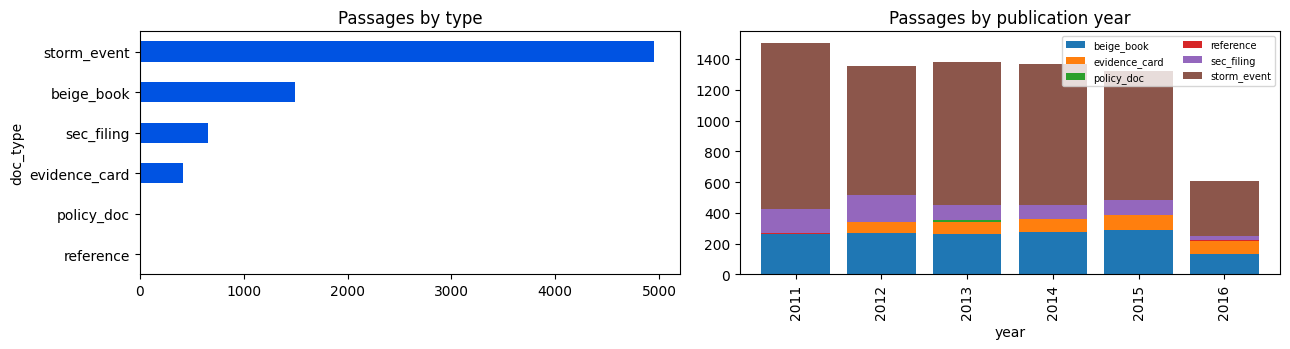

Saved library_passages_v4.csv


,chunk_id,doc_type,source,title,published,state,category,text,year,words
7144,cards-00032-000,evidence_card,Group 4 M5 analysis,Event effect: Labor Day (data to 2011-12-31),2012-01-01,US,ALL,"Calendar event effect: Labor Day (LaborDay), a...",2012,58
7219,cards-00107-000,evidence_card,Group 4 M5 analysis,Event effect: Labor Day (data to 2012-12-31),2013-01-01,US,ALL,"Calendar event effect: Labor Day (LaborDay), a...",2013,59
7301,cards-00189-000,evidence_card,Group 4 M5 analysis,Event effect: Labor Day (data to 2013-12-31),2014-01-01,US,ALL,"Calendar event effect: Labor Day (LaborDay), a...",2014,51
7383,cards-00271-000,evidence_card,Group 4 M5 analysis,Event effect: Labor Day (data to 2014-12-31),2015-01-01,US,ALL,"Calendar event effect: Labor Day (LaborDay), a...",2015,52
7465,cards-00353-000,evidence_card,Group 4 M5 analysis,Event effect: Labor Day (data to 2015-12-31),2016-01-01,US,ALL,"Calendar event effect: Labor Day (LaborDay), a...",2016,53


In [ ]:
try:
    from google.colab import data_table
    data_table.enable_dataframe_formatter()           # interactive, filterable tables in Colab
except Exception:
    pass
import matplotlib.pyplot as plt
library = chunks[["chunk_id", "doc_type", "source", "title", "published", "state", "category", "text"]].copy()
library["year"] = library["published"].dt.year
library["words"] = library["text"].str.split().str.len()

print(f"{len(library):,} passages from {chunks['doc_id'].nunique():,} documents\n")
display(pd.crosstab(library["doc_type"], library["state"], margins=True, margins_name="total"))
display(pd.crosstab(library["doc_type"], library["year"]))
display(library.groupby("category").size().to_frame("passages"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
library["doc_type"].value_counts().plot.barh(ax=axes[0], color="#0053E2"); axes[0].set_title("Passages by type"); axes[0].invert_yaxis()
library.groupby(["year", "doc_type"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[1], width=0.8)
axes[1].set_title("Passages by publication year"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

def find_passages(text=None, doc_type=None, state=None, category=None, start=None, end=None):
    """Filter the library. Every argument is optional; text searches titles and passage text (case-insensitive)."""
    m = pd.Series(True, index=library.index)
    if text:
        m &= library["title"].str.contains(text, case=False) | library["text"].str.contains(text, case=False)
    for col, v in [("doc_type", doc_type), ("state", state), ("category", category)]:
        if v:
            m &= library[col].isin([v] if isinstance(v, str) else v)
    if start:
        m &= library["published"] >= pd.Timestamp(start)
    if end:
        m &= library["published"] <= pd.Timestamp(end)
    return library[m]

def show_passage(chunk_id):
    r = library.set_index("chunk_id").loc[chunk_id]
    print(f"{r['title']}\n{r['doc_type']} | {r['source']} | published {r['published']:%Y-%m-%d} | state {r['state']} | category {r['category']}\n")
    print(r["text"])

library.drop(columns=["year"]).to_csv(out_path("library_passages.csv"), index=False)
print("Saved", os.path.basename(out_path("library_passages.csv")))
find_passages(text="labor day", doc_type="evidence_card").head(10)

In [ ]:
# Examples: change the filters to look at anything in the library
display(find_passages(doc_type="evidence_card", state="WI", category="HOBBIES", start="2015-01-01").head(20))
show_passage(find_passages(text="Revenue concentration", state="CA").iloc[-1]["chunk_id"])

,chunk_id,doc_type,source,title,published,state,category,text,year,words
7367,cards-00255-000,evidence_card,Group 4 M5 analysis,Seasonal pattern: Hobbies sales in Wisconsin b...,2015-01-01,WI,HOBBIES,Seasonal (weekly and yearly) sales pattern. Ho...,2015,72
7414,cards-00302-000,evidence_card,Group 4 M5 analysis,"Price, sales and revenue: Hobbies in Wisconsin...",2015-01-01,WI,HOBBIES,How weekly sales and revenue move with price f...,2015,119
7433,cards-00321-000,evidence_card,Group 4 M5 analysis,Unexpected demand spikes: Hobbies in Wisconsin...,2015-01-01,WI,HOBBIES,Demand spikes for Hobbies items in Wisconsin M...,2015,91
7449,cards-00337-000,evidence_card,Group 4 M5 analysis,Seasonal pattern: Hobbies sales in Wisconsin b...,2016-01-01,WI,HOBBIES,Seasonal (weekly and yearly) sales pattern. Ho...,2016,72
7496,cards-00384-000,evidence_card,Group 4 M5 analysis,"Price, sales and revenue: Hobbies in Wisconsin...",2016-01-01,WI,HOBBIES,How weekly sales and revenue move with price f...,2016,119
7515,cards-00403-000,evidence_card,Group 4 M5 analysis,Unexpected demand spikes: Hobbies in Wisconsin...,2016-01-01,WI,HOBBIES,Demand spikes for Hobbies items in Wisconsin M...,2016,91


Revenue concentration and ordering priority: store CA_4 (52 weeks to 2015-12-31)
evidence_card | Group 4 M5 analysis | published 2016-01-01 | state CA | category ALL

Revenue concentration (Pareto) at M5 store CA_4, 52 weeks to 2015-12-31, estimated as weekly units x weekly price. 80% of revenue came from 1,294 of the 3,010 items that sold (43%); the top 10% of items brought 41% of revenue. Revenue by department: FOODS_3 34%, HOUSEHOLD_1 19%, HOBBIES_1 17%, FOODS_2 14%. Top items: HOBBIES_1_354, HOBBIES_1_147, FOODS_3_202, FOODS_3_120, FOODS_3_090. Priority: review orders for the high-revenue items first, since a stock-out there costs the most revenue; low-revenue items can follow the ordering rule with less review.


## 12. Map of the embedded passages
Each passage's embedding is a list of 384 numbers that captures its meaning. This squeezes them onto a 2-D map (t-SNE): passages about similar things land close together, so clusters show what the library covers (storm reports by state, Beige Book districts, card types). Hover over a dot to see the passage title. Saved as `embedding_map_v4.html` in `RAG FILES/` (open it in a browser). Takes about a minute.

In [ ]:
from sklearn.manifold import TSNE
t0 = time.time()
xy = TSNE(n_components=2, init="pca", perplexity=min(30, max(5, len(EMB) // 50)), random_state=0).fit_transform(np.asarray(EMB, dtype=np.float32))
emb_map = library.assign(x=xy[:, 0], y=xy[:, 1], published=library["published"].dt.strftime("%Y-%m-%d"))
try:
    import plotly.express as px
    fig = px.scatter(emb_map, x="x", y="y", color="doc_type", hover_data={"title": True, "published": True, "state": True, "category": True, "x": False, "y": False},
                     title="Embedded passages (t-SNE map): similar passages are close together", height=650, opacity=0.6)
    fig.update_traces(marker=dict(size=4)); fig.write_html(out_path("embedding_map.html")); fig.show()
except ImportError:
    fig, ax = plt.subplots(figsize=(9, 7))
    for t, g in emb_map.groupby("doc_type"):
        ax.scatter(g["x"], g["y"], s=3, label=t, alpha=0.6)
    ax.legend(markerscale=4); ax.set_title("Embedded passages (t-SNE map)")
    fig.savefig(out_path("embedding_map.png"), dpi=150, bbox_inches="tight"); plt.show()
print(f"Map of {len(emb_map):,} passages ({time.time() - t0:.0f}s)")

Map of 7,537 passages (92s)
